In [89]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np

# Задача 4.1

In [90]:
# Параметры задачи
total_balls = 23
white = 8
blue = 6
red = 9

N_simulations = 10000

In [91]:
def simulate_without_replacement(N_simulations):
    p_estimates = []
    favorable_count = 0

    for n in range(1, N_simulations + 1):
        basket = ['красный'] * red + ['синий'] * blue + ['белый'] * white
        random.shuffle(basket)

        sample = random.sample(basket, 6)
        if all(ball == 'красный' for ball in sample):
            favorable_count += 1

        p_estimates.append(favorable_count / n)

    return p_estimates

def simulate_with_replacement(N_simulations):
    p_estimates = []
    favorable_count = 0

    for n in range(1, N_simulations + 1):
        basket = ['красный'] * red + ['синий'] * blue + ['белый'] * white

        sample = random.choices(basket, k=6)
        if all(ball == 'красный' for ball in sample):
            favorable_count += 1

        p_estimates.append(favorable_count / n)

    return p_estimates

In [92]:
def simulate_event_B_without_replacement(N_simulations):
    p_estimates = []
    favorable_count = 0

    for n in range(1, N_simulations + 1):
        basket = ['красный'] * red + ['синий'] * blue + ['белый'] * white
        sample = random.sample(basket, 6)

        if (sample.count('синий') == 3 and
            sample.count('белый') == 2 and
            sample.count('красный') == 1):
            favorable_count += 1

        p_estimates.append(favorable_count / n)

    return p_estimates


def simulate_event_D_without_replacement(N_simulations):
    p_estimates = []
    favorable_count = 0

    for n in range(1, N_simulations + 1):
        basket = ['красный'] * red + ['синий'] * blue + ['белый'] * white
        sample = random.sample(basket, 6)

        if sample.count('белый') == 4:
            favorable_count += 1

        p_estimates.append(favorable_count / n)

    return p_estimates

In [93]:
P_A_theoretical = math.comb(9, 6) / math.comb(23, 6)

P_B_theoretical = (
    math.comb(6, 3) *
    math.comb(8, 2) *
    math.comb(9, 1)
) / math.comb(23, 6)

P_D_theoretical = (
    math.comb(8, 4) *
    math.comb(15, 2)
) / math.comb(23, 6)

P_G_theoretical = (9 / 23) ** 6

print(f"Теоретическая вероятность для А (без возвращения): {P_A_theoretical:.8f}")
print(f"Теоретическая вероятность Б (3 синих, 2 белых, 1 красный): {P_B_theoretical:.8f}")
print(f"Теоретическая вероятность В (ровно 4 белых): {P_D_theoretical:.8f}")
print(f"Теоретическая вероятность для Г (с возвращением): {P_G_theoretical:.8f}")

Теоретическая вероятность для А (без возвращения): 0.00083212
Теоретическая вероятность Б (3 синих, 2 белых, 1 красный): 0.04992719
Теоретическая вероятность В (ровно 4 белых): 0.07281048
Теоретическая вероятность для Г (с возвращением): 0.00358995


In [94]:
results_A = simulate_without_replacement(N_simulations)
results_B = simulate_event_B_without_replacement(N_simulations)
results_D = simulate_event_D_without_replacement(N_simulations)
results_G = simulate_with_replacement(N_simulations)

print("Оценка после экспериментов:")
print(f"Случай А (без возвращения): {results_A[-1]:.8f}")
print(f"Случай Б (3 синих, 2 белых, 1 красный): {results_B[-1]:.8f}")
print(f"Случай В (ровно 4 белых): {results_D[-1]:.8f}")
print(f"Случай Г (с возвращением): {results_G[-1]:.8f}")

Оценка после экспериментов:
Случай А (без возвращения): 0.00110000
Случай Б (3 синих, 2 белых, 1 красный): 0.05000000
Случай В (ровно 4 белых): 0.07320000
Случай Г (с возвращением): 0.00410000


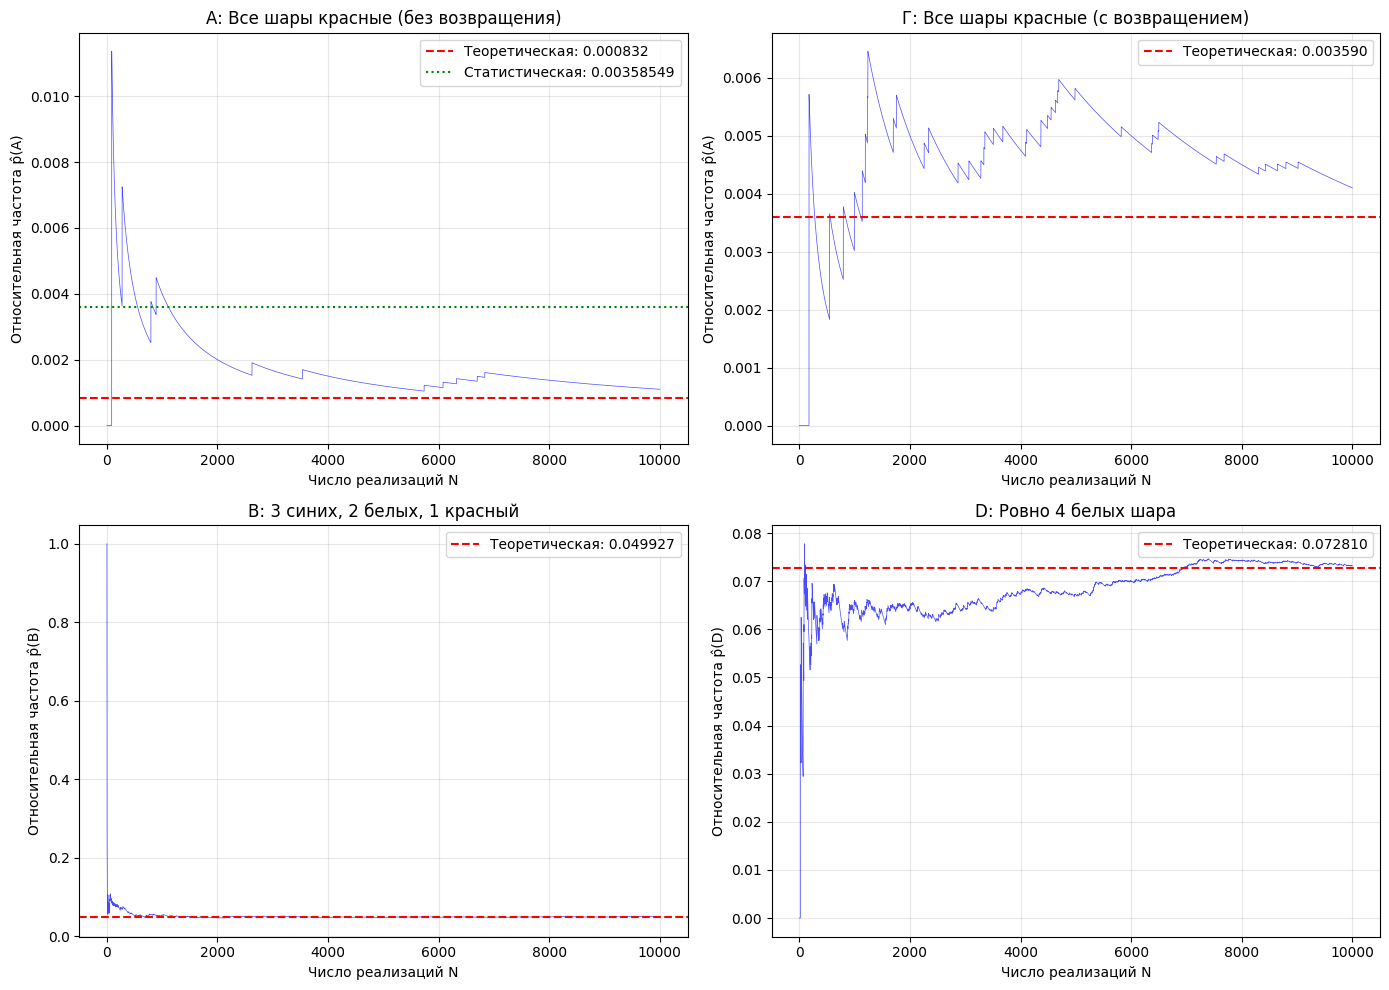

In [95]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.plot(range(1, N_simulations + 1), results_A, 'b-', alpha=0.7, linewidth=0.5)
ax.axhline(y=P_A_theoretical, color='r', linestyle='--', label=f'Теоретическая: {P_A_theoretical:.6f}')
ax.axhline(y=0.00358549, color='g', linestyle=':', label='Статистическая: 0.00358549')
ax.set_xlabel('Число реализаций N')
ax.set_ylabel('Относительная частота p̂(A)')
ax.set_title('A: Все шары красные (без возвращения)')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
ax.plot(range(1, N_simulations + 1), results_G, 'b-', alpha=0.7, linewidth=0.5)
ax.axhline(y=P_G_theoretical, color='r', linestyle='--', label=f'Теоретическая: {P_G_theoretical:.6f}')
ax.set_xlabel('Число реализаций N')
ax.set_ylabel('Относительная частота p̂(A)')
ax.set_title('Г: Все шары красные (с возвращением)')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
ax.plot(range(1, N_simulations + 1), results_B, 'b-', alpha=0.7, linewidth=0.5)
ax.axhline(y=P_B_theoretical, color='r', linestyle='--', label=f'Теоретическая: {P_B_theoretical:.6f}')
ax.set_xlabel('Число реализаций N')
ax.set_ylabel('Относительная частота p̂(B)')
ax.set_title('B: 3 синих, 2 белых, 1 красный')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
ax.plot(range(1, N_simulations + 1), results_D, 'b-', alpha=0.7, linewidth=0.5)
ax.axhline(y=P_D_theoretical, color='r', linestyle='--', label=f'Теоретическая: {P_D_theoretical:.6f}')
ax.set_xlabel('Число реализаций N')
ax.set_ylabel('Относительная частота p̂(D)')
ax.set_title('D: Ровно 4 белых шара')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Задача 4.2

In [96]:
# Общее количество способов рассадить 10 человек
total_arrangements = math.factorial(10)

# Событие A: никакие две женщины не сидят рядом
men_positions = 6

women_positions = math.comb(6, 5)

ways_A = women_positions * math.factorial(5) * math.factorial(5)
P_A = ways_A / total_arrangements

# Событие B: все мужчины сидят рядом
group_arrangements = math.factorial(6)

inside_group = math.factorial(5)

ways_B = group_arrangements * inside_group
P_B = ways_B / total_arrangements

print(f"P(A) = {P_A:.6f}")
print(f"P(B) = {P_B:.6f}")

P(A) = 0.023810
P(B) = 0.023810


# Задача 4.3

In [97]:
p = 0.5

P_A = 0
for k in range(1, 6):
    P_A += (1-p)**(k-1) * p

print(f"P(A) = {P_A:.6f}")

P(A) = 0.968750


# Задача 4.4

In [98]:
def simulate_trial(max_throws=100):
    throws = []
    first = np.random.choice(['H', 'T'])
    throws.append(first)

    while True:
        second = np.random.choice(['H', 'T'])
        throws.append(second)
        if throws[-1] == throws[-2]:
            break
        if len(throws) >= max_throws:
            break
    return len(throws)

In [99]:
N = 100000
count_even = 0
results = []

for i in range(1, N+1):
    num_throws = simulate_trial()
    results.append(num_throws)
    if num_throws % 2 == 0:
        count_even += 1

    if i % 1000 == 0:
        p_even = count_even / i

freq = count_even / N
print(f"P(чётное число бросков) = {freq:.6f}")

P(чётное число бросков) = 0.665240


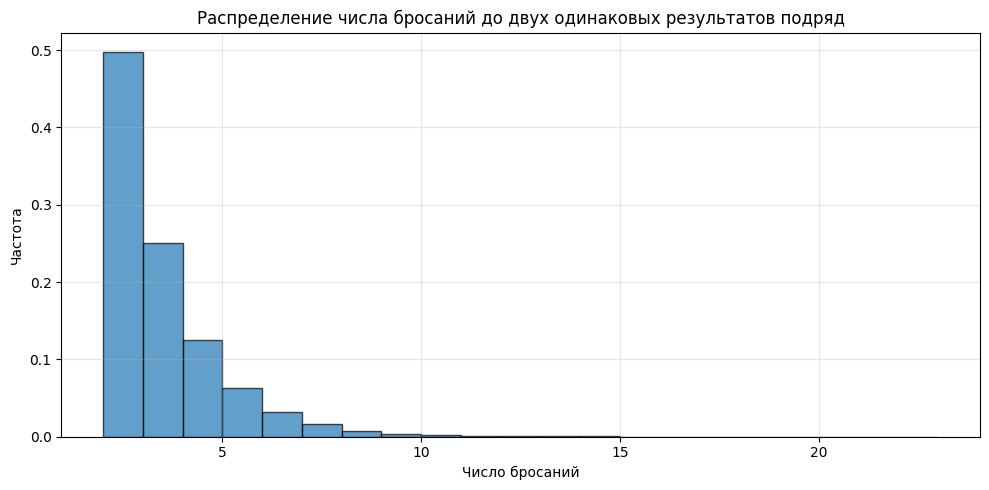

In [100]:
plt.figure(figsize=(10, 5))
plt.hist(results, bins=range(2, max(results)+1), density=True, alpha=0.7, edgecolor='black')
plt.xlabel('Число бросаний')
plt.ylabel('Частота')
plt.title('Распределение числа бросаний до двух одинаковых результатов подряд')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Задача 4.5

In [101]:
def simulate_trial(p=0.7, max_throws=50):
    throws = []
    first = 'H' if np.random.random() < p else 'T'
    throws.append(first)

    while True:
        second = 'H' if np.random.random() < p else 'T'
        throws.append(second)
        if throws[-1] == throws[-2]:
            break
        if len(throws) >= max_throws:
            break
    return len(throws)

In [102]:
p = 0.7
N = 100000
count_even = 0
count_mult4 = 0
results = []

for i in range(N):
    num_throws = simulate_trial(p)
    results.append(num_throws)
    if num_throws % 2 == 0:
        count_even += 1
    if num_throws % 4 == 0:
        count_mult4 += 1

P_even = count_even / N
P_mult4 = count_mult4 / N

print(f"P(чётное число бросков) = {P_even:.6f}")
print(f"P(число бросков кратно 4) = {P_mult4:.6f}")

P(чётное число бросков) = 0.735920
P(число бросков кратно 4) = 0.127390


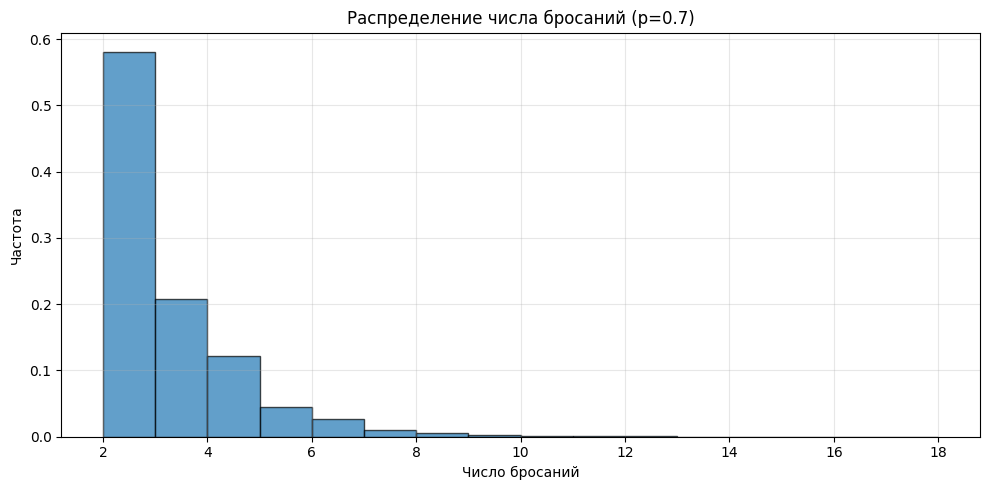

In [103]:
plt.figure(figsize=(10, 5))
plt.hist(results, bins=range(2, max(results)+1), density=True, alpha=0.7, edgecolor='black')
plt.xlabel('Число бросаний')
plt.ylabel('Частота')
plt.title(f'Распределение числа бросаний (p={p})')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Задача 4.6

In [104]:
N = 150000
wait_A = 10 / 60.0
wait_B = 12 / 60.0

t_A = np.random.uniform(0, 1, N)
t_B = np.random.uniform(0, 1, N)

meet = (t_B <= t_A + wait_A) & (t_A <= t_B + wait_B)

cumulative_meet = np.cumsum(meet)
relative_freq = cumulative_meet / np.arange(1, N + 1)

p_hat = relative_freq[-1]

print(f"Оценка вероятности p̂ = {p_hat:.6f}")

Оценка вероятности p̂ = 0.331847


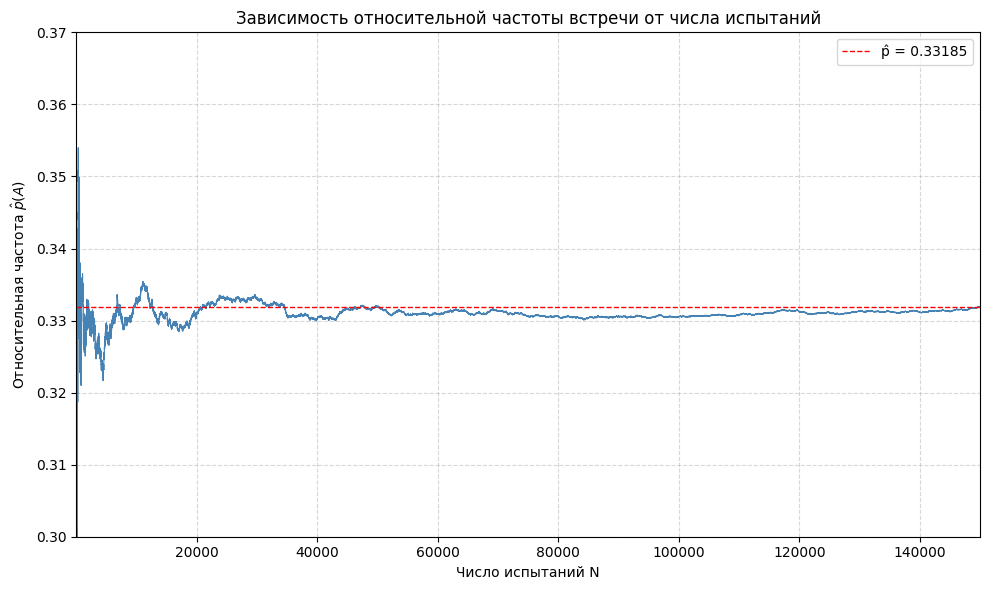

In [105]:
plt.figure(figsize=(10, 6))
plt.plot(relative_freq, color='steelblue', linewidth=0.8)
plt.axhline(y=p_hat, color='red', linestyle='--', linewidth=1, label=f'p̂ = {p_hat:.5f}')
plt.title('Зависимость относительной частоты встречи от числа испытаний')
plt.xlabel('Число испытаний N')
plt.ylabel('Относительная частота $\\hat{p}(A)$')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(1, N)
plt.ylim(0.3, 0.37)
plt.tight_layout()
plt.show()

# Задача 4.7

In [106]:
N = 150000
wait_time = 15/60
success_A = 0
success_B = 0
success_C = 0
success_D = 0
success_E = 0
success_F = 0
frequencies = []

for i in range(1, N+1):
    arrival_Ivan = np.random.uniform(0, 1)
    arrival_Peter = np.random.uniform(0, 1)

    if abs(arrival_Ivan - arrival_Peter) <= wait_time:
        success_A += 1
        if arrival_Ivan >= arrival_Peter:
            success_C += 1

        meet_time = max(arrival_Ivan, arrival_Peter)
        if meet_time > 0.5:
            success_D += 1

        if meet_time > 55/60:
            success_F += 1
    else:
        success_B += 1
        if arrival_Ivan > arrival_Peter + wait_time:
            success_E += 1

    if i % 100 == 0:
        frequencies.append(success_A / i)

p_estimate_A = success_A / N
p_estimate_B = success_B / N
p_estimate_C = success_C / N
p_estimate_D = success_D / N
p_estimate_E = success_E / N
p_estimate_F = success_F / N

print(f"P(A) = {p_estimate_A:.6f}")
print(f"P(B) = {p_estimate_B:.6f}")
print(f"P(C) = {p_estimate_C:.6f}")
print(f"P(D) = {p_estimate_D:.6f}")
print(f"P(E) = {p_estimate_E:.6f}")
print(f"P(F) = {p_estimate_F:.6f}")

P(A) = 0.436753
P(B) = 0.563247
P(C) = 0.219440
P(D) = 0.249607
P(E) = 0.282680
P(F) = 0.041820


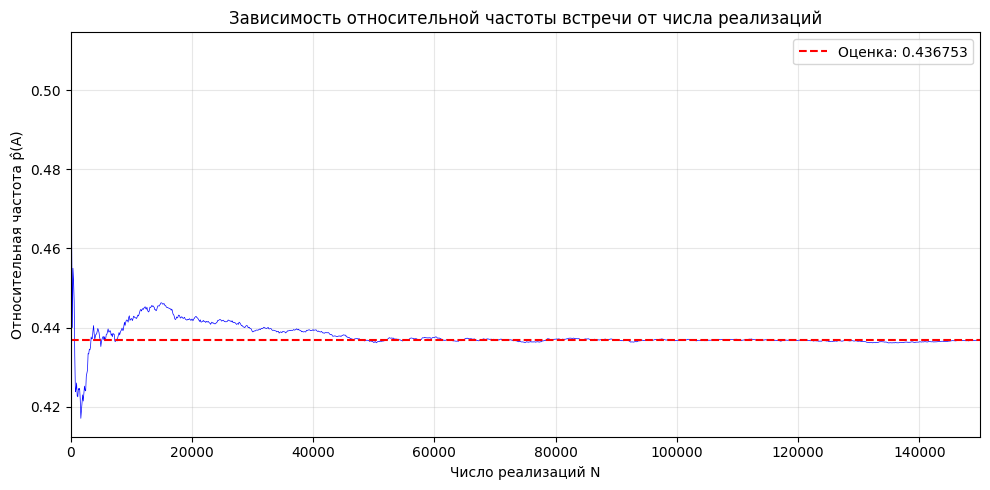

In [107]:
plt.figure(figsize=(10, 5))
plt.plot(range(100, N+1, 100), frequencies, 'b-', linewidth=0.5)
plt.axhline(y=p_estimate_A, color='r', linestyle='--', label=f'Оценка: {p_estimate_A:.6f}')
plt.xlabel('Число реализаций N')
plt.ylabel('Относительная частота p̂(A)')
plt.title('Зависимость относительной частоты встречи от числа реализаций')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, N)
plt.tight_layout()
plt.show()

# Задача 4.8

In [108]:
a, b = 0, 1
N = 150000
count_A = 0
count_B = 0
count_C = 0
frequencies = []

for i in range(1, N+1):
    x = np.random.uniform(a, b)
    y = np.random.uniform(a, x)

    if abs(y - b) < abs(x - a):
        count_A += 1
    if abs(x - y) < (b - a) / 2:
        count_B += 1
    if abs(x - y) < abs(x - b):
        count_C += 1

    if i % 100 == 0:
        frequencies.append(count_A / i)

p_estimate_A = count_A / N
p_estimate_B = count_B / N
p_estimate_C = count_C / N

print(f"P(A) = {p_estimate_A:.6f}")
print(f"P(B) = {p_estimate_B:.6f}")
print(f"P(C) = {p_estimate_C:.6f}")

P(A) = 0.305413
P(B) = 0.846027
P(C) = 0.693387


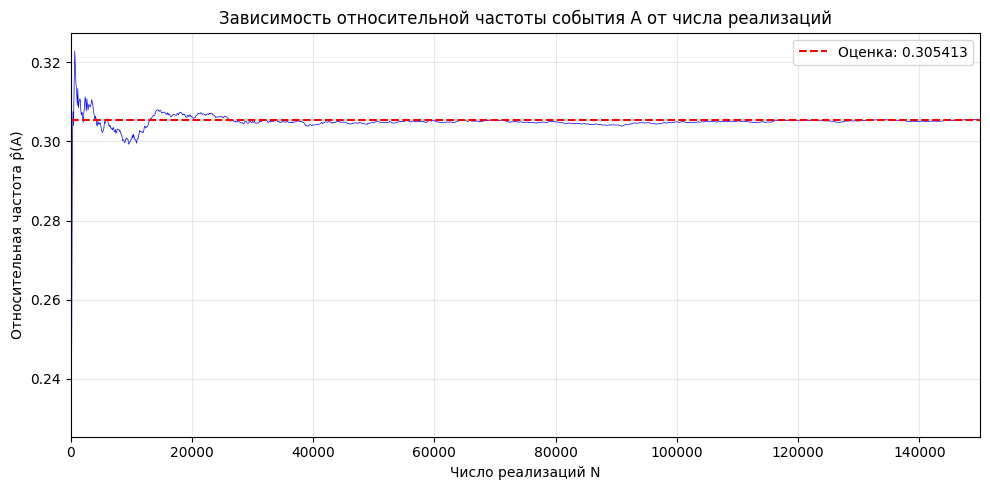

In [109]:
plt.figure(figsize=(10, 5))
plt.plot(range(100, N+1, 100), frequencies, 'b-', linewidth=0.5)
plt.axhline(y=p_estimate_A, color='r', linestyle='--', label=f'Оценка: {p_estimate_A:.6f}')
plt.xlabel('Число реализаций N')
plt.ylabel('Относительная частота p̂(A)')
plt.title('Зависимость относительной частоты события A от числа реализаций')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, N)
plt.tight_layout()
plt.show()

# Задача 4.9

In [110]:
def check_triangle_conditions(a, b, c):
    if not (a + b > c and a + c > b and b + c > a):
        return False

    sides = np.array([a, b, c])
    sides_squared = sides ** 2

    for i in range(3):
        if sides_squared[i] >= sides_squared[(i+1)%3] + sides_squared[(i+2)%3]:
            return False
    return True

def simulate(N=150000):
    successes = 0
    results = []

    for i in range(1, N+1):
        x, y = np.random.random(2)
        x, y = min(x, y), max(x, y)

        a = x
        b = y - x
        c = 1 - y

        if check_triangle_conditions(a, b, c):
            successes += 1

        if i % 1000 == 0:
            results.append(successes / i)

    return successes / N, results

def analytical_solution():
    return 3 * np.log(2) - 2

In [111]:
N = 150000

estimated_prob, relative_frequencies = simulate(N)
analytical_prob = analytical_solution()

print(f"Аналитическая вероятность: {analytical_prob:.10f}")
print(f"Оценка вероятности по моделированию: {estimated_prob:.10f}")
print(f"Абсолютная погрешность: {abs(analytical_prob - estimated_prob):.10f}")
print(f"Относительная погрешность: {abs(analytical_prob - estimated_prob)/analytical_prob*100:.4f}%")

print("\nУсловия для остроугольного треугольника:")
print("1) a + b > c, a + c > b, b + c > a (неравенство треугольника)")
print("2) a² < b² + c², b² < a² + c², c² < a² + b² (остроугольность)")

print("\nПроверка аналитического решения:")
print(f"3 × ln(2) - 2 = 3 × {np.log(2):.6f} - 2 = {analytical_prob:.10f}")

print("\nСравнение для разных N:")
print("-" * 40)
print(f"{'N':>10} | {'Оценка':<12} | {'Погрешность':<12}")
print("-" * 40)

test_N_values = [1000, 5000, 10000, 50000, 100000, 150000, 200000]
for test_N in test_N_values:
    prob, _ = simulate(test_N)
    error = abs(analytical_prob - prob)
    print(f"{test_N:10,} | {prob:.8f}    | {error:.8f}")

Аналитическая вероятность: 0.0794415417
Оценка вероятности по моделированию: 0.0795200000
Абсолютная погрешность: 0.0000784583
Относительная погрешность: 0.0988%

Условия для остроугольного треугольника:
1) a + b > c, a + c > b, b + c > a (неравенство треугольника)
2) a² < b² + c², b² < a² + c², c² < a² + b² (остроугольность)

Проверка аналитического решения:
3 × ln(2) - 2 = 3 × 0.693147 - 2 = 0.0794415417

Сравнение для разных N:
----------------------------------------
         N | Оценка       | Погрешность 
----------------------------------------
     1,000 | 0.07500000    | 0.00444154
     5,000 | 0.07700000    | 0.00244154
    10,000 | 0.07960000    | 0.00015846
    50,000 | 0.07922000    | 0.00022154
   100,000 | 0.08094000    | 0.00149846
   150,000 | 0.07974000    | 0.00029846
   200,000 | 0.08012000    | 0.00067846


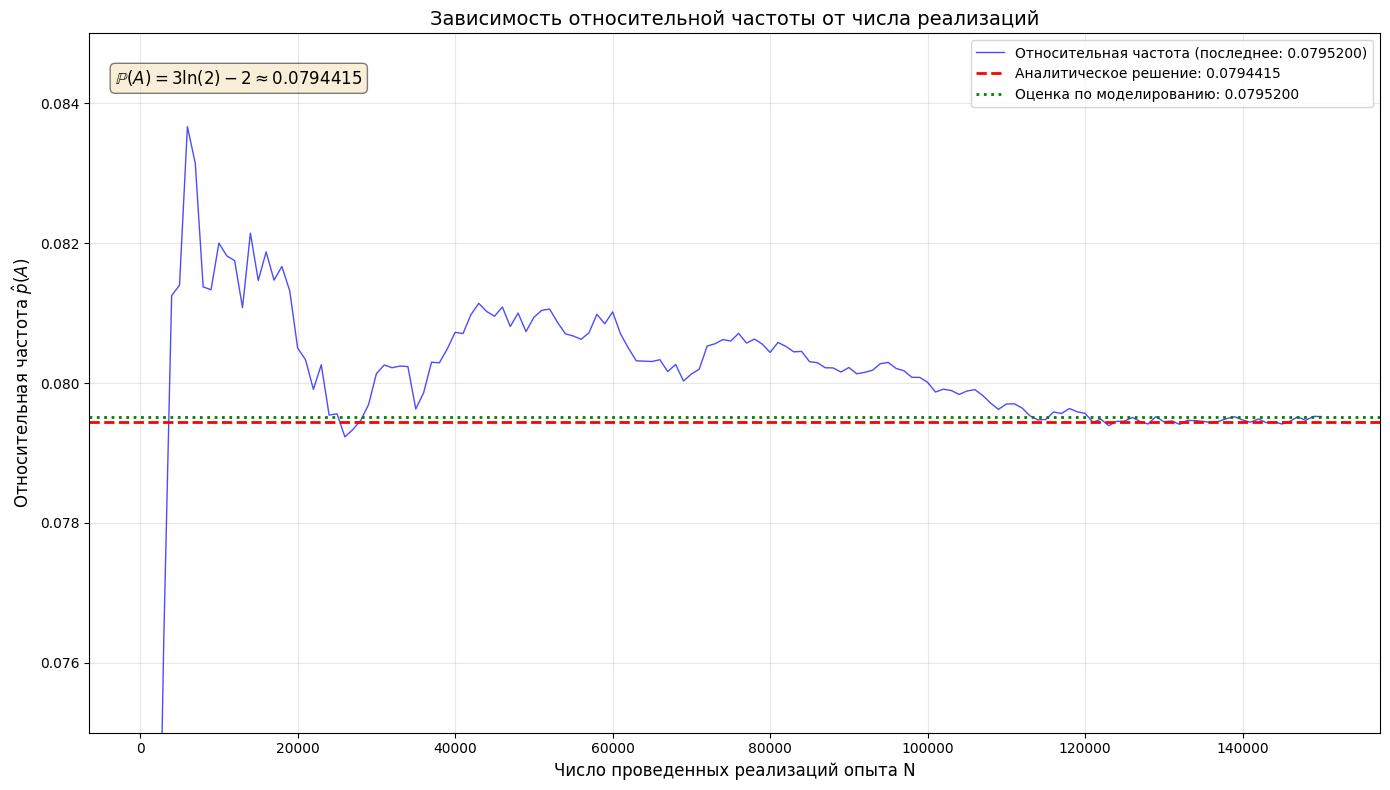

In [112]:
plt.figure(figsize=(14, 8))

x_points = np.linspace(1000, N, len(relative_frequencies))
plt.plot(x_points, relative_frequencies, 'b-', alpha=0.7, linewidth=1,
            label=f'Относительная частота (последнее: {relative_frequencies[-1]:.7f})')

plt.axhline(y=analytical_prob, color='r', linestyle='--', linewidth=2,
            label=f'Аналитическое решение: {analytical_prob:.7f}')

plt.axhline(y=estimated_prob, color='g', linestyle=':', linewidth=2,
            label=f'Оценка по моделированию: {estimated_prob:.7f}')

plt.xlabel('Число проведенных реализаций опыта N', fontsize=12)
plt.ylabel(r'Относительная частота $\hat{p}(A)$', fontsize=12)
plt.title('Зависимость относительной частоты от числа реализаций', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0.075, 0.085)

plt.text(0.02, 0.95, r'$\mathbb{P}(A) = 3\ln(2) - 2 \approx 0.0794415$',
            transform=plt.gca().transAxes, fontsize=12,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# Задача 4.10

In [113]:
def estimate_probability(N=1000000):
    count = 0

    for _ in range(N):
        r1 = np.sqrt(np.random.random())
        angle1 = np.random.uniform(0, 2*np.pi)
        x1, y1 = r1 * np.cos(angle1), r1 * np.sin(angle1)

        r2 = np.sqrt(np.random.random())
        angle2 = np.random.uniform(0, 2*np.pi)
        x2, y2 = r2 * np.cos(angle2), r2 * np.sin(angle2)

        length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        if length < 1:
            count += 1

    return count / N

N = 1000000
p = estimate_probability(N)
print(f"Оценка вероятности для N={N}: {p:.15f}")

Оценка вероятности для N=1000000: 0.586281000000000


# Задача 4.11

In [114]:
def P_all_formula(n, q):
    return n * (q ** (n - 1)) - (n - 1) * (q ** n)

def P_at_least_two_formula_n3(q):
    if q <= 0.5:
        return 1 - (1 - 2*q)**3
    return 1.0

def simulate(n, q, trials=200_000, seed=0):
    random.seed(seed)
    all_meet = 0
    some_pair_meet = 0

    for _ in range(trials):
        xs = [random.random() for _ in range(n)]
        xs.sort()

        if xs[-1] - xs[0] <= q:
            all_meet += 1

        pair = False
        for i in range(n):
            for j in range(i+1, n):
                if abs(xs[j] - xs[i]) <= q:
                    pair = True
                    break
            if pair:
                break
        if pair:
            some_pair_meet += 1

    return all_meet / trials, some_pair_meet / trials

In [115]:
q = 0.3
trials = 300_000

print(f"Пусть q = {q} (это {60*q:.1f} минут ожидания).")
print(f"Делаем Монте-Карло: trials = {trials}\n")

P2 = P_all_formula(2, q)
sim2_all, sim2_pair = simulate(2, q, trials=trials, seed=1)
print("n = 2")
print(f"Формула P2 (встретятся оба):          {P2:.6f}")
print(f"Симуляция P2 (встретятся оба):        {sim2_all:.6f}")
print()

P3 = P_all_formula(3, q)
sim3_all, sim3_pair = simulate(3, q, trials=trials, seed=2)
print("n = 3")
print(f"Формула P3 (встретятся все трое):     {P3:.6f}")
print(f"Симуляция P3 (встретятся все трое):   {sim3_all:.6f}")
print()

P3_pair = P_at_least_two_formula_n3(q)
print("n = 3: встретится хотя бы одна пара")
print(f"Формула (хотя бы двое встретятся):    {P3_pair:.6f}")
print(f"Симуляция (хотя бы двое встретятся):  {sim3_pair:.6f}")

Пусть q = 0.3 (это 18.0 минут ожидания).
Делаем Монте-Карло: trials = 300000

n = 2
Формула P2 (встретятся оба):          0.510000
Симуляция P2 (встретятся оба):        0.509640

n = 3
Формула P3 (встретятся все трое):     0.216000
Симуляция P3 (встретятся все трое):   0.215977

n = 3: встретится хотя бы одна пара
Формула (хотя бы двое встретятся):    0.936000
Симуляция (хотя бы двое встретятся):  0.935430


# Задача 4.12

In [116]:
def P2_formula(w1, w2):
    return 1 - (1 - w1)**2 / 2 - (1 - w2)**2 / 2

def P3_formula(w1, w2, w3):
    w1, w2, w3 = sorted([w1, w2, w3])

    return (
        w1*w2 + w1*w3 + w2*w3
        - 0.5*(w1*(w2**2) + w1*(w3**2) + w2*(w3**2))
        - (1/3)*(w1**3)
        - (1/6)*(w2**3)
    )

def P4_formula(w1, w2, w3, w4):
    w1, w2, w3, w4 = sorted([w1, w2, w3, w4])
    triple_sum = (w1*w2*w3 + w1*w2*w4 + w1*w3*w4 + w2*w3*w4)

    return (
        triple_sum
        - (w2**4)/2 * (w1*w2 + w1*w3 + w2*w3)
        - (w3**3)/6 * (w1 + w2)
        - (w1*w2*(w3**2))/2
        - (w1*(w3**2))/3
        - (w1**4)/4
        - (w2**4)/12
    )

def simulate_all_meet(ws, trials=300_000, seed=0):
    random.seed(seed)
    n = len(ws)
    hits = 0
    for _ in range(trials):
        xs = [random.random() for _ in range(n)]
        left = max(xs)
        right = min(x + w for x, w in zip(xs, ws, strict=False))
        if left <= right:
            hits += 1
    return hits / trials


In [117]:
w1 = 0.25
w2 = 1/3
f = P2_formula(w1, w2)
s = simulate_all_meet([w1, w2], trials=300_000, seed=1)
print("n = 2")
print(f"w1 = {w1}, w2 = {w2}")
print(f"Формула P2  = {f:.6f}")
print(f"Симуляция   = {s:.6f}")
print(f"Разница     = {abs(f-s):.6f}")
print()

w3 = 0.5
f = P3_formula(w1, w2, w3)
s = simulate_all_meet([w1, w2, w3], trials=400_000, seed=2)
print("n = 3")
print(f"w = {w1}, {w2}, {w3} (в формуле сортируем)")
print(f"Формула P3  = {f:.6f}")
print(f"Симуляция   = {s:.6f}")
print(f"Разница     = {abs(f-s):.6f}")
print()

w1, w2, w3 = 1/4, 1/3, 1/2
exact = 1435/5184
f = P3_formula(w1, w2, w3)
s = simulate_all_meet([w1, w2, w3], trials=600_000, seed=4)

print("n=3, w1=1/4, w2=1/3, w3=1/2")
print(f"Формула P3           = {f:.10f}")
print(f"Дано в условии 1435/5184 = {exact:.10f}")
print(f"Симуляция             = {s:.10f}")
print(f"Разница (формула-дано)= {abs(f-exact):.10e}")
print()

w1 = 0.2
w2 = 0.25
w3 = 1/3
w4 = 0.5
f = P4_formula(w1, w2, w3, w4)
s = simulate_all_meet([w1, w2, w3, w4], trials=600_000, seed=3)
print("n = 4")
print(f"w = {w1}, {w2}, {w3}, {w4} (в формуле сортируем)")
print(f"Формула P4  = {f:.6f}")
print(f"Симуляция   = {s:.6f}")
print(f"Разница     = {abs(f-s):.6f}")
print()

n = 2
w1 = 0.25, w2 = 0.3333333333333333
Формула P2  = 0.496528
Симуляция   = 0.496333
Разница     = 0.000194

n = 3
w = 0.25, 0.3333333333333333, 0.5 (в формуле сортируем)
Формула P3  = 0.276813
Симуляция   = 0.276585
Разница     = 0.000228

n=3, w1=1/4, w2=1/3, w3=1/2
Формула P3           = 0.2768132716
Дано в условии 1435/5184 = 0.2768132716
Симуляция             = 0.2756666667
Разница (формула-дано)= 0.0000000000e+00

n = 4
w = 0.2, 0.25, 0.3333333333333333, 0.5 (в формуле сортируем)
Формула P4  = 0.102588
Симуляция   = 0.084730
Разница     = 0.017858



# Задача 4.13

In [118]:
def probability_white(n, p):
    return (n * p + 1) / (n + 1)

def binomial_probability(n, k, p):
    return math.comb(n, k) * (p ** k) * ((1 - p) ** (n - k))

def probability_white_exact(n, p):
    total = 0
    for k in range(n + 1):
        pk = binomial_probability(n, k, p)
        total += pk * (k + 1) / (n + 1)
    return total

In [119]:
n = 10
p = 1 / 3

print("Вероятность того, что извлечённый шар окажется белым:")
print("Теоретический результат:", probability_white(n, p))
print("Через биномиальное распределение:", probability_white_exact(n, p))

Вероятность того, что извлечённый шар окажется белым:
Теоретический результат: 0.3939393939393939
Через биномиальное распределение: 0.39393939393939414


# Задача 4.14

In [120]:
def analytical_PA():
    total = 0

    for k1 in range(4):
        for k2 in range(5):
            prob = (math.comb(3, k1) * (0.8**k1) * (0.2**(3-k1)) *
                    math.comb(4, k2) * (0.7**k2) * (0.3**(4-k2)))


            prob_white = (k1 + k2) / 17

            total += prob * prob_white

    return total

def analytical_PH_given_A():
    prob_H_and_A = 0

    for k1 in range(4):
        for k2 in range(5):
            prob = (math.comb(3, k1) * (0.8**k1) * (0.2**(3-k1)) *
                    math.comb(4, k2) * (0.7**k2) * (0.3**(4-k2)))

            prob_H_and_A += prob * (6/17) * (k1/6)

    PA = analytical_PA()
    return prob_H_and_A / PA

def simulate(trials=1000000):
    count_A = 0
    count_H_and_A = 0

    for _ in range(trials):
        k1 = np.random.binomial(3, 0.8)
        k2 = np.random.binomial(4, 0.7)

        if np.random.random() < 6/17:
            if np.random.random() < k1/6:
                count_A += 1
                count_H_and_A += 1
        else:
            if np.random.random() < k2/11:
                count_A += 1

    PA_sim = count_A / trials
    PH_given_A_sim = count_H_and_A / count_A if count_A > 0 else 0

    return PA_sim, PH_given_A_sim

In [121]:
print("1) P(A) - вероятность вынуть белый шар:")
PA = analytical_PA()
print(f"   {PA:.4f}")

print("\n2) P(H|A) - условная вероятность:")
PH_given_A = analytical_PH_given_A()
print(f"   {PH_given_A:.4f}")

print("\nПроверка моделированием (1,000,000 испытаний):")
PA_sim, PH_given_A_sim = simulate()
print(f"   P(A) симуляция: {PA_sim:.4f}")
print(f"   P(H|A) симуляция: {PH_given_A_sim:.4f}")

1) P(A) - вероятность вынуть белый шар:
   0.3059

2) P(H|A) - условная вероятность:
   0.4615

Проверка моделированием (1,000,000 испытаний):
   P(A) симуляция: 0.3056
   P(H|A) симуляция: 0.4617


# Задача 4.14

In [122]:
def monte_carlo(n=100000):
    x_min, x_max = -20, 20
    y_min, y_max = -8, 8

    x1 = np.random.uniform(x_min, x_max, n)
    y1 = np.random.uniform(y_min, y_max, n)
    x2 = np.random.uniform(x_min, x_max, n)
    y2 = np.random.uniform(y_min, y_max, n)

    distances = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    A = distances < 11
    B = np.abs(x2 - x1) < 14
    P_A = np.mean(A)

    A_and_B = A & B
    P_A_given_B = np.sum(A_and_B) / np.sum(B) if np.sum(B) > 0 else 0

    return round(P_A, 3), round(P_A_given_B, 3)

In [123]:
P_A, P_A_given_B = monte_carlo(100000)

print(f"1) P(A) = {P_A}")
print(f"2) P(A|B) = {P_A_given_B}")

print("\nПроверка с разными случайными выборками:")
for i in range(5):
    np.random.seed(i)
    P_A_i, P_A_given_B_i = monte_carlo(100000)
    print(f"Попытка {i+1}: P(A) = {P_A_i}, P(A|B) = {P_A_given_B_i}")

1) P(A) = 0.368
2) P(A|B) = 0.638

Проверка с разными случайными выборками:
Попытка 1: P(A) = 0.368, P(A|B) = 0.64
Попытка 2: P(A) = 0.368, P(A|B) = 0.641
Попытка 3: P(A) = 0.368, P(A|B) = 0.637
Попытка 4: P(A) = 0.368, P(A|B) = 0.637
Попытка 5: P(A) = 0.368, P(A|B) = 0.636


# Задача 4.16

In [124]:
def monte_carlo(n=100000):
    a, b = 23, 6

    count_A = 0
    count_B = 0
    count_A_and_B = 0
    total_pairs = 0

    for _ in range(n):
        while True:
            u1 = np.random.uniform(-a, a)
            v1 = np.random.uniform(-b, b)
            if (u1/a)**2 + (v1/b)**2 <= 1:
                break

        while True:
            u2 = np.random.uniform(-a, a)
            v2 = np.random.uniform(-b, b)
            if (u2/a)**2 + (v2/b)**2 <= 1:
                break

        distance = np.sqrt((u2 - u1)**2 + (v2 - v1)**2)
        is_A = distance < 9.2
        is_B = (u1 > 0 and v1 > 0) and (u2 < 0 and v2 < 0)

        if is_A:
            count_A += 1
        if is_B:
            count_B += 1
        if is_A and is_B:
            count_A_and_B += 1

        total_pairs += 1

    P_A = count_A / total_pairs
    P_A_given_B = count_A_and_B / count_B if count_B > 0 else 0

    return round(P_A, 2), round(P_A_given_B, 2)

In [125]:
P_A, P_A_given_B = monte_carlo(100000)

print(f"1) P(A) = {P_A}")
print(f"2) P(A|B) = {P_A_given_B}")

1) P(A) = 0.35
2) P(A|B) = 0.07


# Задача 4.17

In [126]:
def monte_carlo(n=100000):
    R_in_T = 0
    S_in_T = 0
    T_total = 0

    for _ in range(n):
        A = np.random.random(3)
        B = np.random.random(3)
        C = np.random.random(3)

        AB = B - A
        AC = C - A
        BC = C - B

        a = np.linalg.norm(BC)
        b = np.linalg.norm(AC)
        c = np.linalg.norm(AB)

        if a + b <= c or a + c <= b or b + c <= a:
            continue

        cos_alpha = (b**2 + c**2 - a**2) / (2*b*c)
        cos_beta = (a**2 + c**2 - b**2) / (2*a*c)
        cos_gamma = (a**2 + b**2 - c**2) / (2*a*b)

        alpha = np.degrees(np.arccos(np.clip(cos_alpha, -1, 1)))
        beta = np.degrees(np.arccos(np.clip(cos_beta, -1, 1)))
        gamma = np.degrees(np.arccos(np.clip(cos_gamma, -1, 1)))

        angles = np.array([alpha, beta, gamma])

        if np.all(angles < 90):
            T_total += 1

            min_angle = np.min(angles)
            max_angle = np.max(angles)

            if min_angle < 26.7:
                R_in_T += 1

            if max_angle < 81.9:
                S_in_T += 1

    P_R_given_T = round(R_in_T / T_total, 2) if T_total > 0 else 0
    P_S_given_T = round(S_in_T / T_total, 2) if T_total > 0 else 0

    return P_R_given_T, P_S_given_T

In [127]:
P1, P2 = monte_carlo(100000)
print(f"1) P(R|T) = {P1}")
print(f"2) P(S|T) = {P2}")

1) P(R|T) = 0.11
2) P(S|T) = 0.66
